# Radio-map extension, round 4: how much of KGNN's edge is learning, and how much is the fixed local-kriging structure?

**Needs next to it (all unchanged):** `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `rmbench_ext2.py`, `rmbench_ext3.py`, plus the round-3 caches in `results_conf3/cache_uji` and `cache_sod`. The ablation layer `rmbench_ablate.py` is **written by section 2 of this notebook** (spawned worker processes must be able to import it); it only adds, nothing earlier is touched. Round 4 does not need `rmbench_ext4.py`.

## Question
Does learning the kernel parameters (`l1, s1, lr, lt, s2, tau`) beat the *same* local-kriging kernel left at its defaults?

## Arms (all Kmax = 12, s2_init = 0.3, common random numbers per unit and labelled set)
| arm | what it is |
|---|---|
| `abl_full` | learned: stock KGNN defaults |
| `abl_untr_polar` | steps = 0, polar term on (untrained local kriging, like-for-like with `abl_full`) |
| `abl_untr_nopolar` | steps = 0, polar term off (= stock `krig_untrained`, checked numerically) |
| `abl_nopolar` | learned, polar term removed |
| `abl_nonug_fixed` | learned, nugget frozen at its default 0.2 |
| `abl_nonug_zero` | learned, nugget frozen at ~0 |
| `abl_nostep0` | learned, but the untrained step-0 checkpoint is not a validation candidate |

## Pre-registered rule (frozen in `results_ablation/prereg_ablation.json` before the first run)
* **Primary:** `abl_full` vs `abl_untr_polar`, pooled real Wi-Fi (UJI + SOD), random and blocked splits, fresh test salt `abl4`, replicate ids 700+, defaults only.
* **LEARNING SUPPORTED** only if the primary is Holm-significant (A better) in *every* split x density cell **and** the layout-level cluster-bootstrap 95 % CI excludes 0 in the same direction in every cell.
* **EQUIVALENT** if the parent-level 95 % CI lies inside +/-2 % in every cell. Otherwise **NOT ESTABLISHED**. Only SUPPORTED allows the sentence "learning improves local kriging".
* Data are the real units of round 3 (not fresh units); salt and replicate ids are fresh. Holm per (family, split) call. Gains in % and dB.

## 1. Setup

In [1]:
import os, sys, json, warnings, shutil
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

def _preflight():
    need = ["rmbench_core.py", "rmbench_nn.py", "rmbench_ext.py", "rmbench_ext2.py", "rmbench_ext3.py"]
    gone = [f for f in need if not os.path.exists(f)]
    if gone: raise FileNotFoundError(f"missing next to the notebook ({os.getcwd()}): {gone}")
_preflight()
for _m in ("rmbench_ext", "rmbench_ext2", "rmbench_ext3", "rmbench_ablate"): sys.modules.pop(_m, None)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
import torch
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2, rmbench_ext3 as r3
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

SMOKE  = False        # True: ~2-5 min dry run on FAKE data (plumbing only, says nothing about science). Output goes to ablation_smoke/, never to figures/.
ROOT   = "results_conf3"   # round-3 output folder: must contain cache_uji/ and/or cache_sod/ (+ prereg_conf3.json). Only READ here.
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
N_REP  = 5            # replicates per (unit, density); ignored in SMOKE (2)
MAX_APS_PER_FLOOR = None   # optional cap to shorten a run; leave None for the pre-registered design

SALT, REP0, MARGIN, SPLITS = "abl4", 700, 2.0, ("random", "blocked")
FIG, OUT = ("ablation_smoke/figures", "ablation_smoke/results") if SMOKE else ("figures", "results_ablation")
print("SMOKE" if SMOKE else "REAL", "| jobs:", N_JOBS, "| torch", torch.__version__, "| out:", OUT, FIG)

REAL | jobs: 15 | torch 2.14.0+cu130 | out: results_ablation figures


## 2. The ablation layer (`rmbench_ablate.py`, written to disk)
`%%writefile` puts the module next to the notebook so the process pool can import it. Re-running the cell overwrites it with the same text. `fit_predict_kgnn_abl` is `fit_predict_kgnn` with switches `polar`, `freeze`, `tau_zero`, `step0`; the seed comes from the labelled indices and a common tag, not from the arm name, so paired differences carry no seed noise.

In [2]:
%%writefile rmbench_ablate.py
"""rmbench_ablate -- KGNN ablation layer. Adds only; rmbench_core / nn / ext / ext2 / ext3 / ext4 stay UNTOUCHED.

Question: how much of KGNN's edge is *learning* and how much is the fixed local-kriging structure?

Variants (all share Kmax=12, s2_init=0.3, lr/wd/steps defaults of the stock `kgnn`; all use the SAME random numbers per (unit, labelled set),
because the seed is derived from the labelled indices and a common tag, not from the job name -> paired differences are not inflated by seed noise):

  abl_full          learned: l1, s1, lr, lt, s2, tau   (= stock kgnn, same defaults, common seed)
  abl_untr_polar    steps=0, polar term ON, default covariance           <- "untrained local kriging", polar kernel (like-for-like with abl_full)
  abl_untr_nopolar  steps=0, polar term OFF                              <- the stock `krig_untrained` (checked against it numerically)
  abl_nopolar       learned, polar term removed
  abl_nonug_fixed   learned, nugget tau frozen at its default (0.2)
  abl_nonug_zero    learned, nugget tau frozen at ~0 (only the 1e-4 jitter stays)
  abl_nostep0       learned, but the step-0 (= untrained kriging) checkpoint is NOT a candidate for validation early stopping
Diagnostic columns written per fit: best_ep (0 = the untrained kriging won the validation, i.e. learning never helped on held-out labels).
"""
from __future__ import annotations
import os, json, time, traceback
import numpy as np
import torch, torch.nn.functional as F
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2, rmbench_ext3 as r3
from rmbench_nn import KGNN, _sp, _isp, _split_val

COMMON = dict(Kmax=12, s2_init=0.3)
ABL_JOBS = [
    dict(name="abl_full",         method="kgnn_abl", hp=dict(COMMON)),
    dict(name="abl_untr_polar",   method="kgnn_abl", hp=dict(COMMON, steps=0, polar=True)),
    dict(name="abl_untr_nopolar", method="kgnn_abl", hp=dict(COMMON, steps=0, polar=False)),
    dict(name="abl_nopolar",      method="kgnn_abl", hp=dict(COMMON, polar=False)),
    dict(name="abl_nonug_fixed",  method="kgnn_abl", hp=dict(COMMON, freeze=["tau"])),
    dict(name="abl_nonug_zero",   method="kgnn_abl", hp=dict(COMMON, freeze=["tau"], tau_zero=True)),
    dict(name="abl_nostep0",      method="kgnn_abl", hp=dict(COMMON, step0=False)),
]

def jobs():
    """Baselines + stock rows (kgnn, krig_untrained: used for a numerical tie-out) + the ablation arms."""
    return rx.base_jobs() + [dict(name="krig_untrained", method="krig_untrained", hp={})] + ABL_JOBS

# ----------------------------------------------------------------------------------------------- the switchable KGNN fit
def fit_predict_kgnn_abl(u, tr, te, prep, hp, seed_unused):
    """fit_predict_kgnn (rmbench_nn) with switches: polar, freeze (list of parameter names), tau_zero, step0. Labels at tr only."""
    seed = rc.stable_hash(u["name"], len(tr), int(np.sum(tr)), hp.get("seed_tag", "abl")) % 100000   # common random numbers across arms
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    Pt = torch.tensor(u["pos"], dtype=torch.float32); tx = torch.tensor(u["tx_xy"], dtype=torch.float32)
    sig = prep["sigma"]; rn = torch.tensor(prep["res"] / sig, dtype=torch.float32)
    Ptr = Pt[tr]; k3 = min(3, len(tr) - 1)
    scale = float(torch.topk(torch.cdist(Ptr, Ptr), k3 + 1, largest=False).values[:, -1].median()) + 1e-6
    Kmax, steps, delta = int(hp.get("Kmax", 12)), int(hp.get("steps", 150)), 1.5
    m = KGNN(polar=bool(hp.get("polar", True)), s2_init=float(hp.get("s2_init", 0.05)))
    if hp.get("tau_zero"):
        with torch.no_grad(): m.tau.fill_(-20.0)                       # softplus(-20) ~ 2e-9
    for nme in hp.get("freeze", []): getattr(m, nme).requires_grad_(False)
    fit, val = _split_val(tr, rng); best_ep = 0
    if steps > 0:
        train_params = [p for p in m.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(train_params, lr=float(hp.get("lr", 1e-2)), weight_decay=float(hp.get("wd", 1e-3)))
        def val_loss():
            m.eval()
            with torch.no_grad():
                return F.huber_loss(m(Pt[val], Pt[fit], rn[fit], scale, tx, min(Kmax, len(fit))), rn[val], delta=delta).item()
        snap = lambda: {k: t.clone() for k, t in m.state_dict().items()}
        if len(val):
            best, state = (val_loss(), snap()) if hp.get("step0", True) else (float("inf"), None)    # step0=False: kriging is NOT a candidate
        else: best, state = float("inf"), None
        for ep in range(steps):
            m.train(); opt.zero_grad(); n = len(fit)
            q = int(np.clip(round(rng.uniform(0.1, 0.5) * n), 2, max(2, min(48, n - 3)))); pp = rng.permutation(fit); qi, ri = pp[:q], pp[q:]
            F.huber_loss(m(Pt[qi], Pt[ri], rn[ri], scale, tx, min(Kmax, len(ri))), rn[qi], delta=delta).backward()
            torch.nn.utils.clip_grad_norm_(train_params, 2.0); opt.step()
            if len(val) and ep % 10 == 9:
                v = val_loss()
                if v < best - 1e-5: best, state, best_ep = v, snap(), ep + 1
        if state is not None: m.load_state_dict(state)
    m.eval(); Kf = min(Kmax, len(tr))
    with torch.no_grad():
        pred = np.concatenate([m(Pt[te[i:i + 1500]], Pt[tr], rn[tr], scale, tx, Kf).numpy() for i in range(0, len(te), 1500)]) * sig
    return pred, dict(steps_run=steps, best_ep=best_ep, l1=float(_sp(m.l1).detach()), s2=float(_sp(m.s2).detach()), tau=float(_sp(m.tau).detach()))

# ----------------------------------------------------------------------------------------------- dispatch (installed inside every worker)
def install():
    """Teach rc.predict_method 'kgnn_abl' (idempotent; chains on whatever is installed). Spawned workers do not inherit patches."""
    r3.install()
    if getattr(rc.predict_method, "_abl", False): return
    orig = rc.predict_method
    def pm(method, hp, u, tr, te, prep, seed=0, graph_cache=None):
        if method == "kgnn_abl":
            p, info = fit_predict_kgnn_abl(u, tr, te, prep, hp, seed); return prep["trend"][te] + p, info
        return orig(method, hp, u, tr, te, prep, seed, graph_cache)
    pm._abl = True; pm._ext3 = True; rc.predict_method = pm

def run_task_abl(task):
    install(); return r2.run_task_ext2(task)

def run_tasks_abl(tasks, out_path, n_jobs=1, log_every=25):
    """Resumable JSONL executor (same protocol as r3.run_tasks3) dispatching run_task_abl."""
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    done = rc.done_task_ids(out_path); todo = [t for t in tasks if t["id"] not in done]
    print(f"[run_tasks_abl] {len(tasks)} tasks, {len(tasks) - len(todo)} done, {len(todo)} to run (n_jobs={n_jobs}) -> {out_path}")
    t0, nf, shown = time.time(), 0, False
    enc = lambda o: None if o != o else float(o) if isinstance(o, np.floating) else str(o)
    def write(rows, fh):
        nonlocal nf, shown
        bad = [r for r in rows if r["status"] != "ok"]; nf += len(bad)
        if bad and not shown: shown = True; print(f"  first failure: {bad[0].get('name')} {bad[0].get('unit')}\n{bad[0].get('err', '')}")
        fh.write(json.dumps(rows, default=enc) + "\n"); fh.flush()
    def fail(t): return [dict(task_id=t["id"], unit=t["unit"], density=t["density"], rep=t["rep"], name=j["name"], method=j["method"], status="fail",
                              err=traceback.format_exc(limit=2)) for j in t["jobs"]]
    with open(out_path, "a") as fh:
        if n_jobs <= 1:
            for i, t in enumerate(todo, 1):
                write(run_task_abl(t), fh)
                if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")
        else:
            from concurrent.futures import ProcessPoolExecutor, as_completed
            import multiprocessing as mp
            with ProcessPoolExecutor(n_jobs, mp_context=mp.get_context("spawn"), initializer=rc._init_worker) as ex:
                futs = {ex.submit(run_task_abl, t): t for t in todo}
                for i, f in enumerate(as_completed(futs), 1):
                    try: rows = f.result()
                    except Exception: rows = fail(futs[f])
                    write(rows, fh)
                    if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")

Writing rmbench_ablate.py


In [3]:
import rmbench_ablate as ab
print([j['name'] for j in ab.jobs()])

['trend', 'idw', 'krig_global', 'kgnn', 'krig_untrained', 'abl_full', 'abl_untr_polar', 'abl_untr_nopolar', 'abl_nopolar', 'abl_nonug_fixed', 'abl_nonug_zero', 'abl_nostep0']


## 3. Design constants and contrasts

In [4]:
SALT, REP0, MARGIN, SPLITS = "abl4", 700, 2.0, ("random", "blocked")
PRIMARY = ("abl_full", "abl_untr_polar")
CONTRASTS = [PRIMARY,
             ("abl_full", "abl_untr_nopolar"),        # vs the stock krig_untrained configuration
             ("abl_full", "abl_nopolar"),             # value of the learned polar term
             ("abl_full", "abl_nonug_fixed"),         # value of learning the nugget (vs default 0.2)
             ("abl_full", "abl_nonug_zero"),          # value of having a nugget at all
             ("abl_full", "abl_nostep0"),             # value of the step-0 early-stopping candidate
             ("abl_nopolar", "abl_untr_nopolar"),     # learning effect without the polar term
             ("abl_untr_polar", "abl_untr_nopolar"),  # polar term effect without learning
             ("abl_untr_polar", "krig_global"), ("abl_untr_polar", "idw"),
             ("abl_full", "krig_global"), ("abl_full", "idw")]
LABEL = {PRIMARY: "LEARNING: full vs untrained polar kriging [PRIMARY]", CONTRASTS[1]: "full vs stock krig_untrained (no polar)",
         CONTRASTS[2]: "learned polar term (full vs no polar)", CONTRASTS[3]: "learned nugget (vs fixed 0.2)", CONTRASTS[4]: "nugget at all (vs ~0)",
         CONTRASTS[5]: "step-0 candidate (full vs without)", CONTRASTS[6]: "learning, no polar term", CONTRASTS[7]: "polar term, no learning",
         CONTRASTS[8]: "untrained polar kriging vs global kriging", CONTRASTS[9]: "untrained polar kriging vs IDW",
         CONTRASTS[10]: "full KGNN vs global kriging", CONTRASTS[11]: "full KGNN vs IDW"}
ORDER = ["trend", "idw", "krig_global", "abl_untr_nopolar", "abl_untr_polar", "abl_nonug_zero", "abl_nonug_fixed", "abl_nopolar", "abl_nostep0", "abl_full"]
COLOR = dict(zip(ORDER, ["#9aa0a6", "#1f77b4", "#ff7f0e", "#c7b9e2", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#17becf", "#d62728"]))

## 4. Families (real Wi-Fi units of round 3, or fake units in SMOKE)

In [5]:
def families(smoke, root, n_rep):
    if smoke:
        root = "ablation_smoke"; shutil.rmtree(root, ignore_errors=True); os.makedirs(root)
        base = dict(rx.UJI_CFG, densities=(10, 20, 30), n_test=25, min_unit_points=50, uji_max_waps_per_floor=2, outage_q=(0.25, 0.5), outage_abs_dbm=(),
                    outage_min_class=8, trend_policy="robust", seed=3, test_salt=SALT)
        fu = {}
        d = r2.read_uji(rx.make_fake_uji(f"{root}/fake_uji", floors=(2, 2, 2), n_waps=12)); cu = dict(base, cache_dir=f"{root}/cache_uji")
        fu["uji"] = dict(names=r3.build_wifi_units3(d, cu, "uji", **r2.UJI_COLS)[0], cfg=cu)
        s = r3.read_sod(r3.make_fake_sod(f"{root}/fake_sod")); cs = dict(base, cache_dir=f"{root}/cache_sod")
        fu["sod"] = dict(names=r3.build_wifi_units3(s, cs, "sod", **r3.SOD_COLS, wprefix=r3.SOD_PREFIX)[0], cfg=cs)
        return fu, 2, 8
    fam = dict(uji=dict(densities=(5, 10, 20), n_test=20), sod=dict(densities=(5, 10, 20, 60), n_test=20))
    pj = os.path.join(root, "prereg_conf3.json")
    if os.path.exists(pj):
        spec = json.load(open(pj))["spec"]["families"]
        for t in fam:
            if t in spec: fam[t] = dict(densities=tuple(spec[t]["densities"]), n_test=int(spec[t]["n_test"]))
        print("densities / n_test read from", pj, "->", fam)
    else: print(f"WARNING: {pj} not found; using densities/n_test {fam}. Check them against your round-3 notebook output.")
    fu = {}
    for t in ("uji", "sod"):
        cd = os.path.join(root, f"cache_{t}"); names = sorted(r3.units_in_cache(cd))
        if not names: print(f"  no units in {cd} -> family {t} skipped"); continue
        cfg = dict(rx.UJI_CFG, cache_dir=cd, densities=fam[t]["densities"], n_test=fam[t]["n_test"], outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8,
                   trend_policy="robust", seed=3, test_salt=SALT)
        fu[t] = dict(names=names, cfg=cfg)
    return fu, n_rep, 10 ** 9

def usable(fu, max_units_per_parent=None):
    """Drop units too short to give max-density labels plus a few test points (shorter test sets are handled by split_for2); optionally cap APs per building-floor (keeps the quick runs quick)."""
    for t, fd in fu.items():
        cfg, keep, drop = fd["cfg"], [], []
        for n in fd["names"]:
            u = rx.get_unit_ext(n, cfg["cache_dir"]); (keep if len(u["y"]) >= max(cfg["densities"]) + 5 else drop).append(n)
        if max_units_per_parent:
            by = {}
            for n in keep: by.setdefault(rx.get_unit_ext(n, cfg["cache_dir"])["parent"], []).append(n)
            keep = [n for v in by.values() for n in v[:max_units_per_parent]]
        fd["names"] = keep
        U = [rx.get_unit_ext(n, cfg["cache_dir"]) for n in keep]
        print(f"{t}: {len(keep)} units, {len({u['parent'] for u in U})} building-floors, {len({u['layout'] for u in U})} buildings (dropped {len(drop)} too short)")
    return fu

## 5. Pre-registration, run, load

In [6]:
def prereg(fu, reps):
    spec = dict(title="KGNN ablation on real Wi-Fi: learning vs fixed local-kriging structure", primary=list(PRIMARY), contrasts=[list(c) for c in CONTRASTS],
                arms=[j["name"] for j in ab.jobs()], arm_hp={j["name"]: j.get("hp", {}) for j in ab.ABL_JOBS}, splits=list(SPLITS), test_salt=SALT,
                reps=list(range(REP0, REP0 + reps)), equivalence_margin_pct=MARGIN, tuning="none (defaults only)",
                families={t: dict(n_units=len(fd["names"]), densities=list(fd["cfg"]["densities"]), n_test=fd["cfg"]["n_test"], cache=fd["cfg"]["cache_dir"]) for t, fd in fu.items()},
                holm="per (family, split) call; cap = contrasts x densities x scenarios",
                wording="SUPPORTED needs Holm-significant primary in every split x density cell of pooled real_wifi AND layout-level bootstrap CI > 0 in every cell; "
                        "EQUIVALENT needs parent-level 95% CI inside +/-2% in every cell; else NOT ESTABLISHED.",
                note="designed after rounds 1-3 (the question follows from the DeepMIMO tables); data are NOT fresh units, test salt and replicate ids are fresh.")
    os.makedirs(OUT, exist_ok=True); return r2.write_prereg(spec, os.path.join(OUT, "prereg_ablation.json"))

def run(fu, reps, n_jobs):
    res = {}
    for t, fd in fu.items():
        for split in SPLITS:
            cfg = {**fd["cfg"], "split_mode": split, "block_buffer": 0.0, "test_salt": SALT}
            tasks = r2.make_tasks2(fd["names"], cfg["densities"], list(range(REP0, REP0 + reps)), ab.jobs(), cfg, prefix=f"abl|{t}|{split}")
            ab.run_tasks_abl(tasks, os.path.join(OUT, f"abl_{t}_{split}.jsonl"), n_jobs)
    return res

def load(fu):
    R = {}
    for t in fu:
        for s in SPLITS:
            p = os.path.join(OUT, f"abl_{t}_{s}.jsonl")
            if os.path.exists(p): R[(t, s)] = rc.read_results(p)
    return R

## 6. Analysis and verdict

In [7]:
def analyse(R):
    os.makedirs(FIG, exist_ok=True); PC, CL, RM = {}, {}, {}
    fams = {}
    for (t, s), df in R.items(): fams[(t, s)] = df
    for s in SPLITS:
        mem = {t: R[(t, s)] for t in ("uji", "sod") if (t, s) in R}
        if len(mem) == 2: fams[("real_wifi", s)] = r3.pool_real(mem, sorted(set.intersection(*[set(d.density.unique()) for d in mem.values()])))
    for (t, s), df in fams.items():
        d = df[df.status == "ok"]; n_bad = len(df) - len(d)
        print(f"\n##### {t} | {s}: {len(d)} ok rows" + (f", {n_bad} FAILED" if n_bad else ""))
        if n_bad: print(df[df.status != "ok"].groupby("name").size().to_string())
        if d.empty: continue
        tab = rx.agg_metric(d, "rmse"); tab.to_csv(f"{FIG}/abl_{t}_{s}_rmse_table.csv"); r2._show(tab[[c for c in ORDER if c in tab]], "RMSE (dB), parent-level mean")
        pc = r3.contrast_report3(d, CONTRASTS, f"abl_{t}_{s}", FIG, MARGIN)
        cl = r3.layout_level_table(d, CONTRASTS); cl.to_csv(f"{FIG}/abl_{t}_{s}_layout_level.csv", index=False)
        PC[(t, s)], CL[(t, s)], RM[(t, s)] = pc, cl, tab
        # numerical tie-outs: the ablation arms must reproduce the stock rows
        w = rc.unit_level(d).pivot_table(index=["scenario", "parent", "density"], columns="name", values="rmse")
        if {"krig_untrained", "abl_untr_nopolar"} <= set(w): print(f"  tie-out krig_untrained vs abl_untr_nopolar: max |dRMSE| = {(w.krig_untrained - w.abl_untr_nopolar).abs().max():.2e} dB (must be ~0)")
        if {"kgnn", "abl_full"} <= set(w): print(f"  tie-out kgnn vs abl_full (same defaults, different seeds): mean dRMSE = {(w.abl_full - w.kgnn).mean():+.3f} dB, mean |.| = {(w.abl_full - w.kgnn).abs().mean():.3f}")
    return fams, PC, CL, RM

def verdict(PC, CL, fam="real_wifi"):
    rows = []
    for s in SPLITS:
        if (fam, s) not in PC or PC[(fam, s)] is None or not len(PC[(fam, s)]): continue
        pc, cl = PC[(fam, s)], CL[(fam, s)]; p = pc[(pc.A == PRIMARY[0]) & (pc.B == PRIMARY[1])]
        for _, r in p.iterrows():
            c = cl[(cl.density == r.density) & (cl.A == PRIMARY[0]) & (cl.B == PRIMARY[1])]
            lay_ok = bool(len(c) and c.iloc[0].ci_lo > 0); n_lay = int(c.iloc[0].n_layouts) if len(c) else 0
            rows.append(dict(split=s, density=int(r.density), rel_gain_pct=r.rel_gain_pct, delta_db=r.mean_delta_db, p_holm=r.p_holm, n_parents=int(r.n_units),
                             better=bool(r.significant and r.mean_delta_db > 0), worse=bool(r.significant and r.mean_delta_db < 0), layout_ci_gt0=lay_ok, n_layouts=n_lay,
                             equivalent=bool(r.equivalent)))
    v = pd.DataFrame(rows)
    if v.empty: return v, "NO DATA"
    if (v.better & v.layout_ci_gt0 & (v.n_layouts >= r3.MIN_LAYOUTS_CLAIM)).all(): s = "LEARNING SUPPORTED"
    elif v.equivalent.all() and (v.n_parents >= r3.MIN_PARENTS_EQUIV).all(): s = "LEARNING EQUIVALENT TO ZERO (within +/-2%)"
    elif v.worse.any(): s = "NOT ESTABLISHED (learning is significantly WORSE in at least one cell)"
    else: s = "NOT ESTABLISHED"
    return v, s

## 7. Figures

In [8]:
def heat(ax, pc, title):
    ds = sorted(pc.density.unique()); M = np.full((len(CONTRASTS), len(ds)), np.nan); T = [[""] * len(ds) for _ in CONTRASTS]
    for i, c in enumerate(CONTRASTS):
        for j, dd in enumerate(ds):
            r = pc[(pc.A == c[0]) & (pc.B == c[1]) & (pc.density == dd)]
            if len(r):
                r = r.iloc[0]; M[i, j] = r.rel_gain_pct; T[i][j] = f"{r.rel_gain_pct:+.1f}%\n{r.mean_delta_db:+.2f} dB" + ("*" if r.significant else "")
    v = max(3.0, np.nanmax(np.abs(M))) if np.isfinite(M).any() else 3.0
    ax.imshow(M, cmap="RdBu", vmin=-v, vmax=v, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if T[i][j]: ax.text(j, i, T[i][j], ha="center", va="center", fontsize=7, color="white" if abs(M[i, j]) > .65 * v else "black")
    ax.set_xticks(range(len(ds))); ax.set_xticklabels([f"{d} labels" for d in ds]); ax.set_yticks(range(len(CONTRASTS))); ax.set_yticklabels([LABEL[c] for c in CONTRASTS], fontsize=7.5)
    ax.set_title(title, fontsize=9); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)

def figures(fams, PC, RM, v, status):
    plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130, "savefig.bbox": "tight"})
    # 1. heat maps of every contrast, per family (rows = contrast, cols = density, one panel per split)
    for fam in ("real_wifi", "uji", "sod"):
        sp = [s for s in SPLITS if (fam, s) in PC and PC[(fam, s)] is not None and len(PC[(fam, s)])]
        if not sp: continue
        fig, axs = plt.subplots(1, len(sp), figsize=(5.6 * len(sp) + 2.6, 5.2), squeeze=False)
        for ax, s in zip(axs[0], sp): heat(ax, PC[(fam, s)], f"{fam} | {s} split")
        for ax in axs[0][1:]: ax.set_yticklabels([])
        fig.suptitle(f"KGNN ablation, {fam}: relative RMSE gain of A over B (% and dB); positive = A better, * = Holm-significant", fontsize=9.5, y=1.0)
        fig.savefig(f"{FIG}/abl_fig1_contrasts_{fam}.png"); plt.close(fig)
    # 2. RMSE vs labels for every arm (pooled real Wi-Fi, per split)
    sp = [s for s in SPLITS if ("real_wifi", s) in RM]
    if sp:
        fig, axs = plt.subplots(1, len(sp), figsize=(5.2 * len(sp), 3.6), squeeze=False)
        for ax, s in zip(axs[0], sp):
            t = RM[("real_wifi", s)].droplevel(0)
            for k in [c for c in ORDER if c in t]: ax.plot(t.index, t[k], "-o", ms=3.5, lw=2.2 if k in ("abl_full", "abl_untr_polar", "idw") else 1.1, color=COLOR[k], label=k, ls="--" if k == "trend" else "-")
            ax.set_xscale("log"); ax.set_xticks(list(t.index)); ax.set_xticklabels(list(t.index)); ax.set_xlabel("labelled points per unit"); ax.set_title(f"pooled real Wi-Fi | {s}", fontsize=9.5)
        axs[0][0].set_ylabel("RMSE (dB), parent-level mean"); axs[0][-1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.savefig(f"{FIG}/abl_fig2_rmse_vs_labels.png"); plt.close(fig)
    # 3. did learning ever leave step 0?  share of fits whose validation-selected checkpoint is NOT the untrained kriging
    rows = []
    for (t, s), df in fams.items():
        if t == "real_wifi" or "best_ep" not in df: continue
        d = df[(df.status == "ok") & (df.name == "abl_full")]; d = d.assign(moved=(d.best_ep > 0).astype(float))
        rows += [dict(family=t, split=s, density=k, moved=g.moved.mean(), n=len(g)) for k, g in d.groupby("density")]
    if rows:
        D = pd.DataFrame(rows); D.to_csv(f"{FIG}/abl_step0_share.csv", index=False)
        fig, ax = plt.subplots(figsize=(6.2, 3.2)); keys = sorted(set(zip(D.family, D.split))); w = 0.8 / max(1, len(keys)); dens = sorted(D.density.unique())
        for i, (t, s) in enumerate(keys):
            g = D[(D.family == t) & (D.split == s)].set_index("density").reindex(dens)
            ax.bar(np.arange(len(dens)) + (i - (len(keys) - 1) / 2) * w, g.moved, w, label=f"{t} | {s}")
        ax.set_xticks(range(len(dens))); ax.set_xticklabels(dens); ax.set_ylim(0, 1); ax.set_xlabel("labelled points per unit"); ax.set_ylabel("share of fits that left step 0")
        ax.set_title("abl_full: how often does learning beat the untrained kriging on held-out labels?", fontsize=9); ax.legend(fontsize=7, frameon=False)
        fig.savefig(f"{FIG}/abl_fig3_share_left_step0.png"); plt.close(fig)
    # 4. primary contrast per building (pooled family), descriptive
    for s in SPLITS:
        if ("real_wifi", s) not in fams: continue
        g = r3.per_layout_gain(fams[("real_wifi", s)], *PRIMARY)
        if len(g): g.to_csv(f"{FIG}/abl_primary_per_building_{s}.csv")
    # 5. verdict
    v.to_csv(f"{FIG}/abl_primary_cells.csv", index=False)
    txt = [f"# KGNN ablation verdict\n", f"**Primary contrast** `{PRIMARY[0]}` vs `{PRIMARY[1]}` (learning vs the same kernel untrained), pooled real Wi-Fi, both splits.\n",
           f"**Status: {status}**\n", "```\n" + (v.round(4).to_string(index=False) if len(v) else "no cells") + "\n```", "\n",
           "Wording allowed by the frozen rule:\n",
           "- SUPPORTED -> \"learning the kernel parameters improves on untrained local kriging on real Wi-Fi\" (give the % and dB per density).\n"
           "- EQUIVALENT / NOT ESTABLISHED -> the honest headline is \"local kriging with a few learned parameters\"; do not call the method a GNN result.\n"]
    open(f"{FIG}/abl_verdict.md", "w").write("\n".join(txt))
    print("\n" + "=" * 100 + f"\nPRIMARY (learning vs untrained polar kriging, pooled real Wi-Fi): {status}\n" + (v.round(3).to_string(index=False) if len(v) else "") + "\n" + "=" * 100)

## 8. Build the families and freeze the plan

In [9]:
fu, reps, _ = families(SMOKE, ROOT, 2 if SMOKE else N_REP)
if not fu: raise SystemExit(f"no units found: check ROOT (needs {ROOT}/cache_uji and/or {ROOT}/cache_sod from round 3)")
fu = usable(fu, None if SMOKE else MAX_APS_PER_FLOOR)
PRE = prereg(fu, reps)      # a changed plan raises
print("reps:", reps)

densities / n_test read from results_conf3/prereg_conf3.json -> {'uji': {'densities': (5, 10, 20), 'n_test': 20}, 'sod': {'densities': (5, 10, 20, 60), 'n_test': 40}}
uji: 66 units, 11 building-floors, 3 buildings (dropped 0 too short)
sod: 47 units, 5 building-floors, 3 buildings (dropped 0 too short)
reps: 5


## 9. Run (resumable; one JSONL per family and split under `results_ablation/`)
Safe to interrupt and re-run: finished tasks are skipped. Use `SMOKE = True` first.

In [10]:
run(fu, reps, 2 if SMOKE else N_JOBS)

[run_tasks_abl] 990 tasks, 0 done, 990 to run (n_jobs=15) -> results_ablation/abl_uji_random.jsonl
  25/990 15s failed jobs: 0
  50/990 19s failed jobs: 0
  75/990 23s failed jobs: 0
  100/990 27s failed jobs: 0
  125/990 31s failed jobs: 0
  150/990 35s failed jobs: 0
  175/990 40s failed jobs: 0
  200/990 43s failed jobs: 0
  225/990 48s failed jobs: 0
  250/990 52s failed jobs: 0
  275/990 55s failed jobs: 0
  300/990 60s failed jobs: 0
  325/990 64s failed jobs: 0
  350/990 67s failed jobs: 0
  375/990 72s failed jobs: 0
  400/990 76s failed jobs: 0
  425/990 80s failed jobs: 0
  450/990 84s failed jobs: 0
  475/990 88s failed jobs: 0
  500/990 92s failed jobs: 0
  525/990 97s failed jobs: 0
  550/990 101s failed jobs: 0
  575/990 104s failed jobs: 0
  600/990 108s failed jobs: 0
  625/990 112s failed jobs: 0
  650/990 116s failed jobs: 0
  675/990 121s failed jobs: 0
  700/990 125s failed jobs: 0
  725/990 128s failed jobs: 0
  750/990 133s failed jobs: 0
  775/990 137s failed job

{}

## 10. Results
Tie-outs must read ~0 for `krig_untrained` vs `abl_untr_nopolar` (same code path); `kgnn` vs `abl_full` differ only by seed.

In [11]:
R = load(fu); fams, PC, CL, RM = analyse(R)


##### uji | random: 11880 ok rows

=== RMSE (dB), parent-level mean
name               trend    idw  krig_global  abl_untr_nopolar  abl_untr_polar  abl_nonug_zero  abl_nonug_fixed  abl_nopolar  abl_nostep0  abl_full
scenario density                                                                                                                                   
uji      5        10.219  9.070        9.371             8.832           8.826           8.830            8.765        8.997        8.864     8.864
         10        8.154  7.606        7.555             7.384           7.389           7.541            7.355        7.401        7.385     7.385
         20        7.244  6.825        6.764             6.824           6.837           7.036            6.776        6.744        6.745     6.750

=== abl_uji_random | rmse | CONFIRMATORY | 36 tests, Holm over all (rel_gain>0: A better; CI in % of RMSE_B)
   scenario  density               A                 B  n_units  rel_gain_pct  ci

### 10a. Primary verdict (mechanical, from the frozen rule)

In [12]:
v, status = verdict(PC, CL)
figures(fams, PC, RM, v, status)
display(v.round(4))
print(status)


PRIMARY (learning vs untrained polar kriging, pooled real Wi-Fi): NOT ESTABLISHED
  split  density  rel_gain_pct  delta_db  p_holm  n_parents  better  worse  layout_ci_gt0  n_layouts  equivalent
 random        5        -0.898    -0.080   1.000         16   False  False          False          6        True
 random       10        -0.158    -0.011   1.000         16   False  False          False          6        True
 random       20         1.012     0.066   0.193         16   False  False           True          6        True
blocked        5        -0.445    -0.046   1.000         16   False  False          False          6        True
blocked       10        -1.144    -0.105   0.811         16   False  False          False          6       False
blocked       20        -0.231    -0.020   1.000         16   False  False          False          6        True


,split,density,rel_gain_pct,delta_db,p_holm,n_parents,better,worse,layout_ci_gt0,n_layouts,equivalent
0,random,5,-0.8981,-0.0801,1.0000,16,False,False,False,6,True
1,random,10,-0.1578,-0.0115,1.0000,16,False,False,False,6,True
2,random,20,1.0123,0.0663,0.1929,16,False,False,True,6,True
3,blocked,5,-0.4454,-0.0458,1.0000,16,False,False,False,6,True
4,blocked,10,-1.1445,-0.1055,0.8113,16,False,False,False,6,False
5,blocked,20,-0.2311,-0.0198,1.0000,16,False,False,False,6,True


NOT ESTABLISHED


### 10b. Figures
Contrast heat maps (positive = A better, `*` = Holm-significant), RMSE vs labels for every arm, and the share of `abl_full` fits whose validation-selected checkpoint left step 0 (`best_ep > 0`).

figures/abl_fig1_contrasts_real_wifi.png


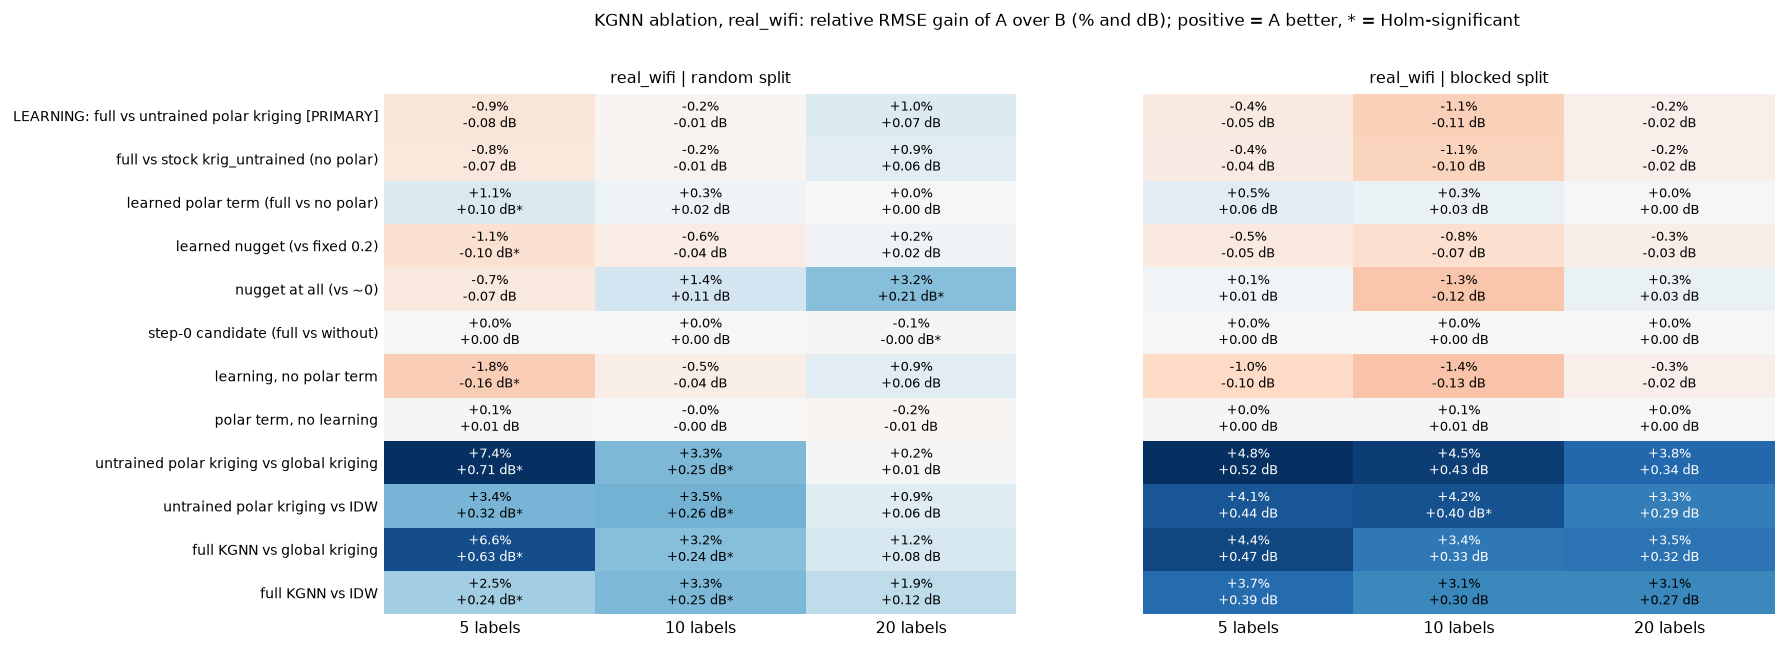

figures/abl_fig1_contrasts_sod.png


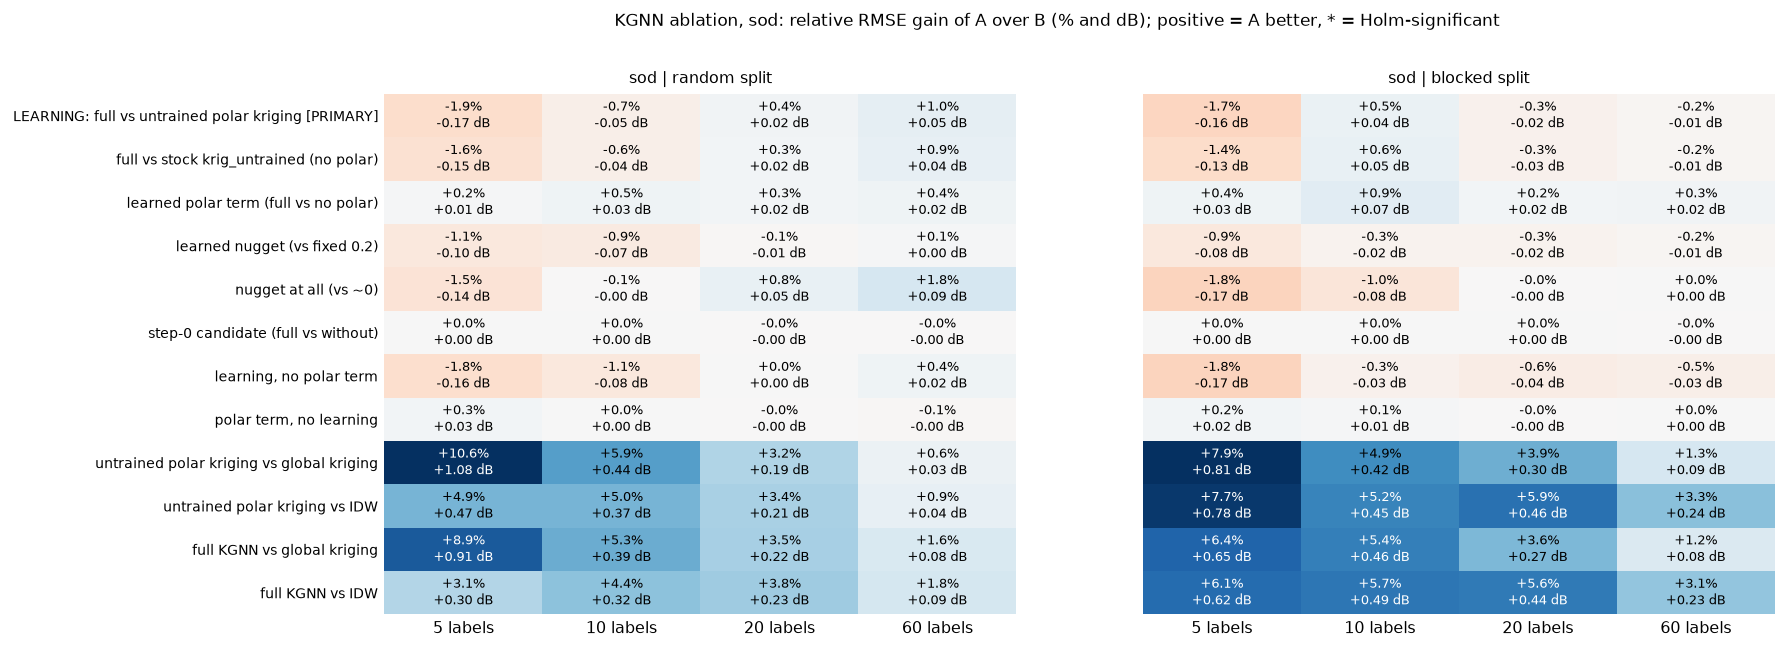

figures/abl_fig1_contrasts_uji.png


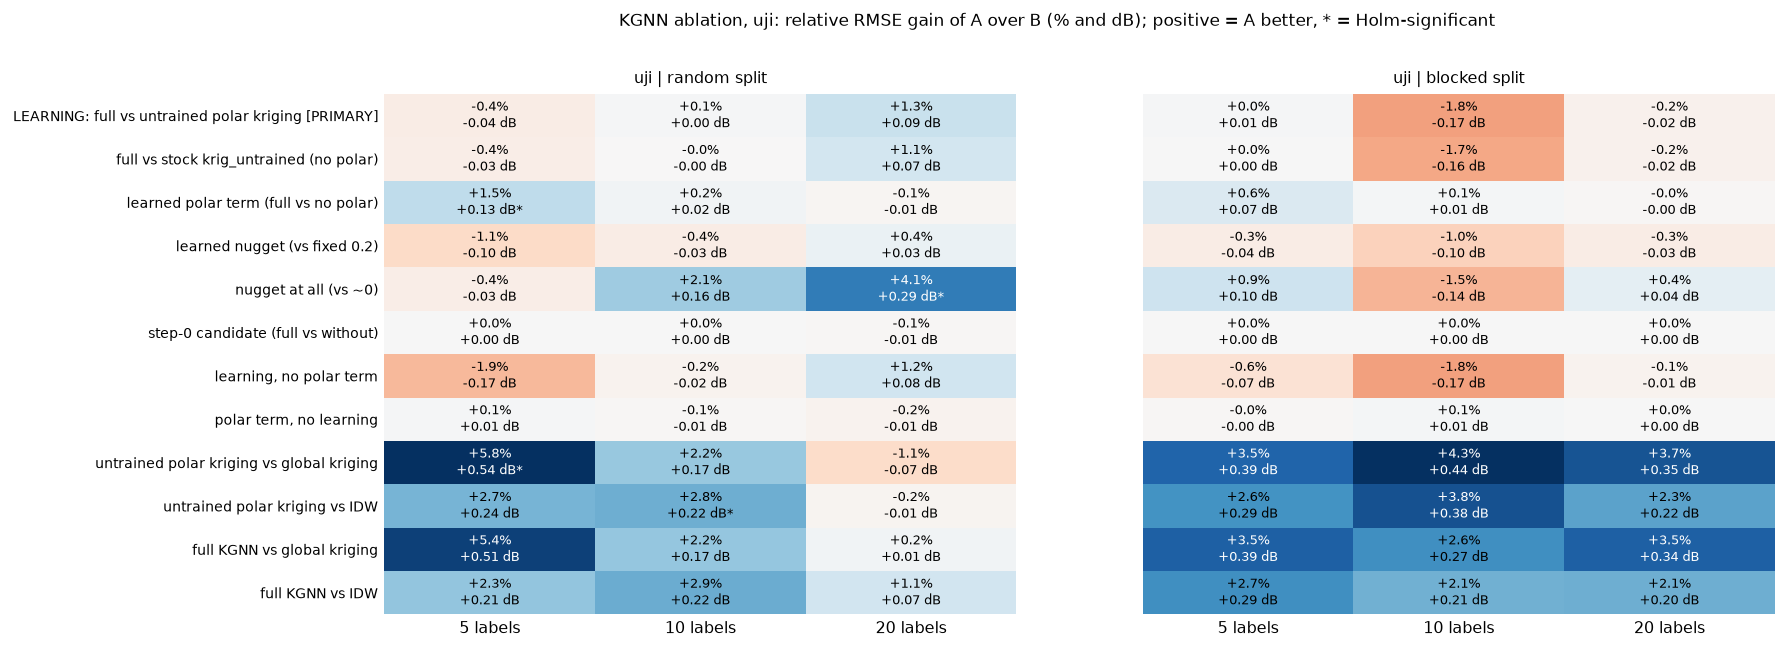

figures/abl_fig2_rmse_vs_labels.png


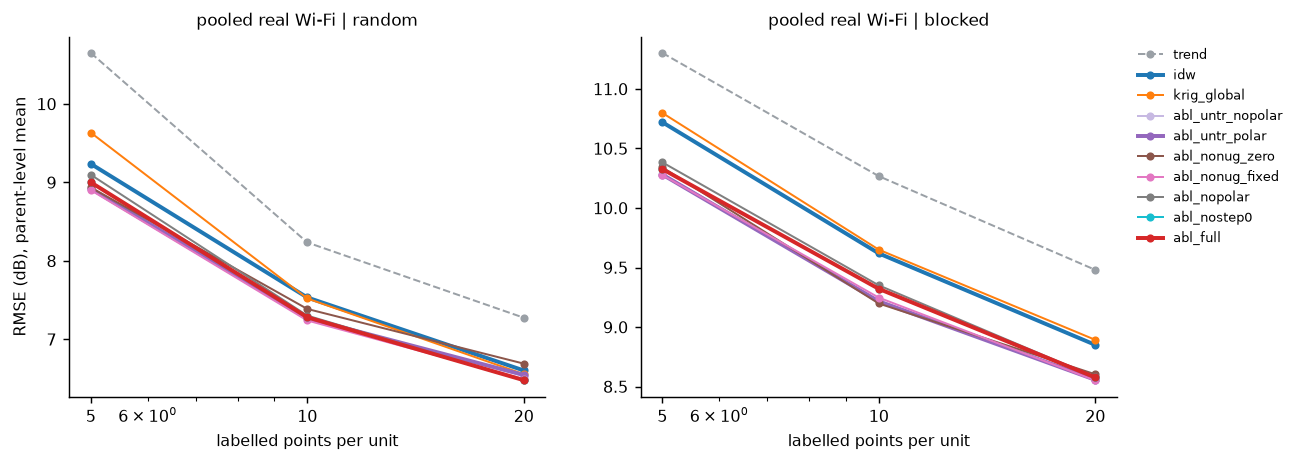

figures/abl_fig3_share_left_step0.png


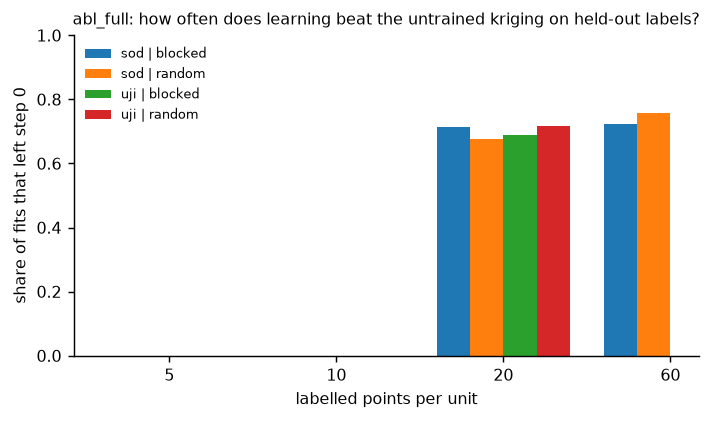

# KGNN ablation verdict

**Primary contrast** `abl_full` vs `abl_untr_polar` (learning vs the same kernel untrained), pooled real Wi-Fi, both splits.

**Status: NOT ESTABLISHED**

```
  split  density  rel_gain_pct  delta_db  p_holm  n_parents  better  worse  layout_ci_gt0  n_layouts  equivalent
 random        5       -0.8981   -0.0801  1.0000         16   False  False          False          6        True
 random       10       -0.1578   -0.0115  1.0000         16   False  False          False          6        True
 random       20        1.0123    0.0663  0.1929         16   False  False           True          6        True
blocked        5       -0.4454   -0.0458  1.0000         16   False  False          False          6        True
blocked       10       -1.1445   -0.1055  0.8113         16   False  False          False          6       False
blocked       20       -0.2311   -0.0198  1.0000         16   False  False          False          6        True
```


Wording allowed by 

In [13]:
import glob
for p in sorted(glob.glob(f"{FIG}/abl_fig*.png")): print(p); display(Image(p))
print(open(f"{FIG}/abl_verdict.md").read())

## 11. What this round can and cannot establish
* **Not fresh units.** The question follows from the round 1-3 tables, so the data are the round-3 units; only the test salt and replicate ids are new.
* **Statistical unit is the building-floor** (APs of a floor share walls); the layout-level (building) bootstrap is the stricter check, and with few buildings its CI is wide.
* **If the verdict is EQUIVALENT or NOT ESTABLISHED,** the honest headline is "local kriging with a few learned parameters", not a GNN result.
* **`best_ep = 0`** means the untrained kriging won validation: learning never helped on held-out labels for that fit. A high share of such fits explains a null primary.
* **Defaults only.** No arm is tuned; a tuned `abl_full` could differ.